In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('../data/checking-logs.sqlite')

In [2]:
query = """
SELECT uid, timestamp 
FROM checker 
WHERE uid LIKE 'user_%' AND labname = 'project1' AND status = 'ready'
"""


In [3]:
df = pd.read_sql_query(query, conn)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['date'] = df['timestamp'].dt.date

In [4]:
daily_commits = df.groupby(['date', 'uid']).size().unstack(fill_value=0)
cumulative_commits = daily_commits.cumsum()

In [5]:
cumulative_melted = cumulative_commits.reset_index().melt(id_vars=['date'], 
                                                         var_name='uid', 
                                                         value_name='cumulative_commits')

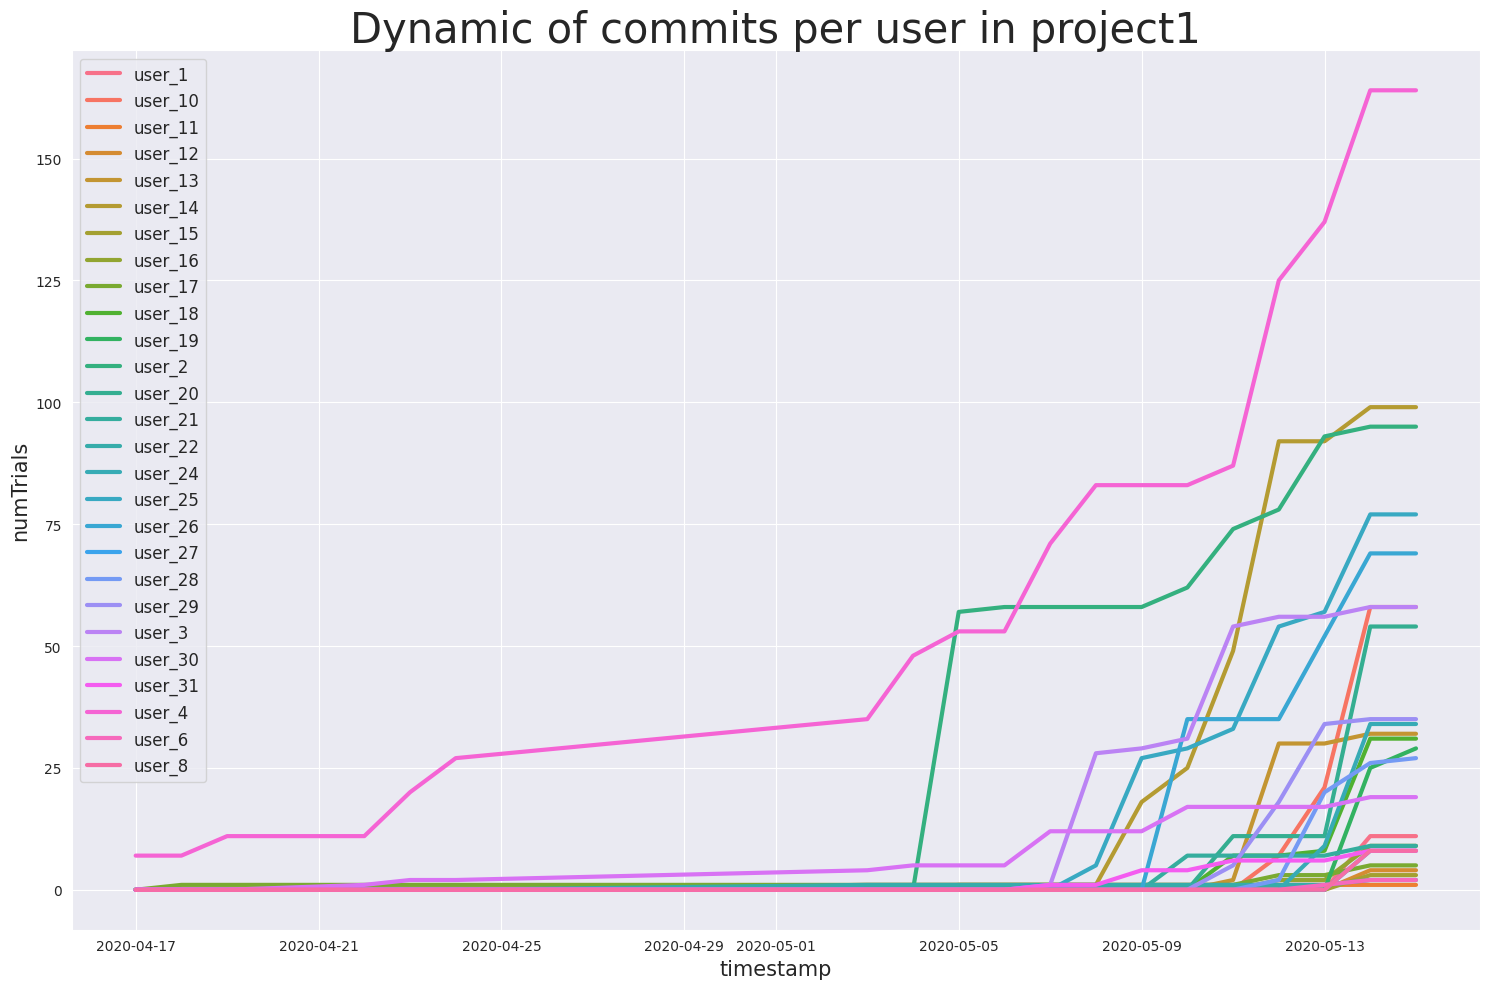

In [6]:
plt.figure(figsize=(15, 10))
sns.set_style("darkgrid")

palette = sns.color_palette("husl", n_colors=df['uid'].nunique())
sns.lineplot(data=cumulative_melted, x='date', y='cumulative_commits', 
             hue='uid', linewidth=3, palette=palette)

plt.xlabel('timestamp', fontsize=15)
plt.ylabel('numTrials', fontsize=15)
plt.title('Dynamic of commits per user in project1', fontsize=30)
plt.legend(fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

conn.close()



### Question
**Which user was the leader in the number of commits almost all of the time?**  
Answer: user_4

**Which user was the leader for only a short period of time?**  
Answer: user_14